Genetic Algorithm Results
-------------------------
Optimal Variables (x, y): [ 0.00031403 -0.00058971]
Maximum Fitness Achieved: 100.000000


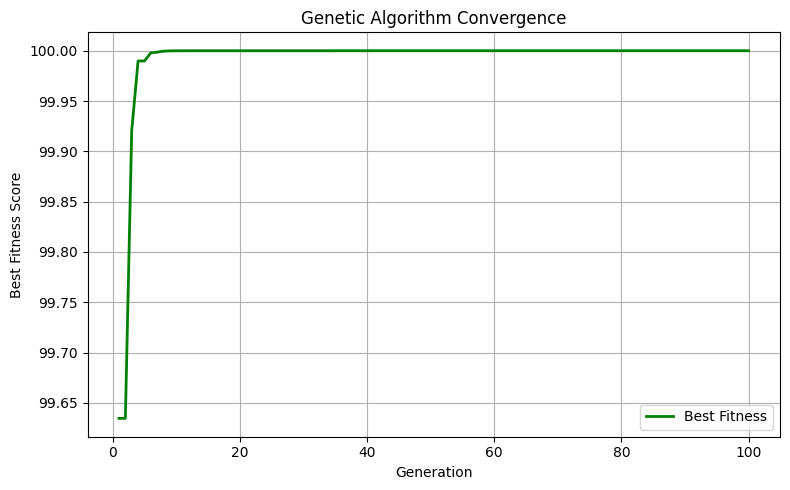

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Define the Problem (Fitness Function)
# ---------------------------------------------------------
def fitness_function(chromosome):
    x, y = chromosome
    return 100 - (x**2 + y**2)


# ---------------------------------------------------------
# 2. Initialize Parameters
# ---------------------------------------------------------
POPULATION_SIZE = 50
GENES = 2
GENERATIONS = 100
MUTATION_RATE = 0.1
CROSSOVER_RATE = 0.8
BOUNDS = [-10.0, 10.0]


# ---------------------------------------------------------
# 3. Create Initial Population
# ---------------------------------------------------------
def create_population(size, bounds):
    return np.random.uniform(
        bounds[0], bounds[1], (size, GENES)
    )


# ---------------------------------------------------------
# 4. Evaluate Fitness
# ---------------------------------------------------------
def evaluate_population(population):
    return np.array([
        fitness_function(individual)
        for individual in population
    ])


# ---------------------------------------------------------
# 5. Selection (Tournament Selection)
# ---------------------------------------------------------
def selection(population, fitnesses, k=3):
    selected_indices = np.random.choice(
        len(population), k, replace=False
    )

    best_index = selected_indices[
        np.argmax(fitnesses[selected_indices])
    ]

    return population[best_index].copy()


# ---------------------------------------------------------
# 6. Crossover (Blend Crossover)
# ---------------------------------------------------------
def crossover(parent1, parent2):
    if np.random.rand() < CROSSOVER_RATE:
        alpha = np.random.rand()

        child1 = alpha * parent1 + (1 - alpha) * parent2
        child2 = (1 - alpha) * parent1 + alpha * parent2

        return child1, child2

    return parent1.copy(), parent2.copy()


# ---------------------------------------------------------
# 7. Mutation (Gaussian Mutation)
# ---------------------------------------------------------
def mutation(child, bounds):
    for i in range(len(child)):
        if np.random.rand() < MUTATION_RATE:
            child[i] += np.random.normal(0, 1.0)

            child[i] = np.clip(
                child[i], bounds[0], bounds[1]
            )

    return child


# ---------------------------------------------------------
# 8. Genetic Algorithm (Main Loop)
# ---------------------------------------------------------
def genetic_algorithm():

    population = create_population(POPULATION_SIZE, BOUNDS)

    best_solution = None
    best_fitness = -np.inf

    history = []

    for generation in range(GENERATIONS):

        # Evaluate fitness
        fitnesses = evaluate_population(population)

        # Find the best individual in current generation
        current_best_idx = np.argmax(fitnesses)

        current_best_fitness = fitnesses[current_best_idx]
        current_best_solution = population[current_best_idx].copy()

        # Update global best solution
        if current_best_fitness > best_fitness:
            best_fitness = current_best_fitness
            best_solution = current_best_solution.copy()

        # Store best fitness
        history.append(best_fitness)

        # Create next generation using elitism
        next_population = [best_solution.copy()]

        while len(next_population) < POPULATION_SIZE:

            # Select parents
            parent1 = selection(population, fitnesses)
            parent2 = selection(population, fitnesses)

            # Crossover
            child1, child2 = crossover(parent1, parent2)

            # Mutation
            child1 = mutation(child1, BOUNDS)
            child2 = mutation(child2, BOUNDS)

            # Add offspring
            next_population.append(child1)

            if len(next_population) < POPULATION_SIZE:
                next_population.append(child2)

        population = np.array(next_population)

    return best_solution, best_fitness, history


# ---------------------------------------------------------
# 9. Execute Genetic Algorithm
# ---------------------------------------------------------
best_sol, best_fit, progress = genetic_algorithm()


# ---------------------------------------------------------
# 10. Display Results
# ---------------------------------------------------------
print("Genetic Algorithm Results")
print("-------------------------")

print(f"Optimal Variables (x, y): {best_sol}")
print(f"Maximum Fitness Achieved: {best_fit:.6f}")


# ---------------------------------------------------------
# 11. Visualize Convergence
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    progress,
    color='green',
    linewidth=2,
    label='Best Fitness'
)

plt.title("Genetic Algorithm Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Fitness Score")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
